# BiSI multi-objective Bayesian optimization with Ax

Use the BiSI XRD target-phase purity and normalized crystallinity as separate optimization objectives. Candidate inputs are hard-bake temperature, bismuth precursor concentration, and atomic S:Bi and I:Bi ratios. The unassigned/overlap detected-area penalty is a screening proxy, not a phase fraction. The candidate search is limited to observed recipe values; outputs are exploratory and should be reviewed before selecting experiments.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from xrd_bo_optimization_tf.bayesian_opt import prepare_optimization_data
from xrd_bo_optimization_tf.config import (
    BO_PARAMETER_COLUMNS,
    GENERATED_XRD_METRICS_CSV,
    NOMAD_SYNTHESIS_CSV,
    UNASSIGNED_AREA_DIAGNOSTICS_CSV,
    UNASSIGNED_AREA_PENALTY_LAMBDA,
)

metrics = pd.read_csv(GENERATED_XRD_METRICS_CSV)
synthesis = pd.read_csv(NOMAD_SYNTHESIS_CSV)
diagnostics = pd.read_csv(UNASSIGNED_AREA_DIAGNOSTICS_CSV)

df_bo = prepare_optimization_data(
    metrics,
    parameter_columns=BO_PARAMETER_COLUMNS,
    synthesis=synthesis,
    include_process=True,
    diagnostics=diagnostics,
    unassigned_area_penalty_lambda=UNASSIGNED_AREA_PENALTY_LAMBDA,
)
df_bo["phase_purity_screened"] = df_bo["phase_purity"] * df_bo["objective_penalty_factor"]
df_bo["crystallinity_norm_screened"] = df_bo["crystallinity_norm"] * df_bo["objective_penalty_factor"]
BO_PARAMS = list(df_bo.attrs["parameter_columns"])
AX_PARAMETER_GRIDS = {
    name: sorted(df_bo[name].dropna().astype(float).unique().tolist())
    for name in BO_PARAMS
}
print(f"Ax BiSI search dimensions: {BO_PARAMS}")
print(f"Complete observations: {len(df_bo)}; screening penalty λ={UNASSIGNED_AREA_PENALTY_LAMBDA:.2f}")
print("Each input uses observed levels only; no untested interpolation grid is assumed.")
df_bo[["sample_id", *BO_PARAMS, "phase_purity_screened", "crystallinity_norm_screened"]].head()

Ax BiSI search dimensions: ['hard_bake_temp_c', 'bismuth_concentration_mol_l', 's_to_bi_molar_ratio', 'i_to_bi_molar_ratio']
Complete observations: 25; screening penalty λ=0.25
Each input uses observed levels only; no untested interpolation grid is assumed.


,sample_id,hard_bake_temp_c,bismuth_concentration_mol_l,s_to_bi_molar_ratio,i_to_bi_molar_ratio,phase_purity_screened,crystallinity_norm_screened
0,260408A1,170.0,0.533863,0.982289,1.046516,1.0,0.213307
1,260408A2,190.0,0.533863,0.982289,1.046516,1.0,0.384954
2,260408A3,210.0,0.533863,0.982289,1.046516,1.0,0.428119
6,260413A10,310.0,0.533863,0.982289,1.046516,1.0,0.361941
7,260413A7,250.0,0.533863,0.982289,1.046516,1.0,0.369325


In [2]:
from ax.service.ax_client import AxClient, ObjectiveProperties

ax_client = AxClient(verbose_logging=False)
ax_parameters = [
    {
        "name": name,
        "type": "choice",
        "values": AX_PARAMETER_GRIDS[name],
        "value_type": "float",
        "is_ordered": True,
    }
    for name in BO_PARAMS
]

ax_client.create_experiment(
    name="bisi_xrd_moo_observed_recipe_inputs",
    parameters=ax_parameters,
    objectives={
        "phase_purity_screened": ObjectiveProperties(
            minimize=False,
            threshold=float(df_bo["phase_purity_screened"].min()),
        ),
        "crystallinity_norm_screened": ObjectiveProperties(
            minimize=False,
            threshold=float(df_bo["crystallinity_norm_screened"].min()),
        ),
    },
)
print(f"Ax multi-objective BiSI experiment created with {len(BO_PARAMS)} inputs")
print("Objectives: maximize screening-adjusted phase purity and crystallinity")

/home/nomad-lanasc/bisi-xrd-optimization/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/tmp/ipykernel_2286845/3638964933.py:3: DeprecationWarning: The `AxClient` class is deprecated and will be removed in Ax 1.4.0. Please migrate to the modern Ax API / `Client` class, found under ax/api. For example usage, check out the tutorials at https://ax.dev 
  ax_client = AxClient(verbose_logging=False)
[INFO 10-30 18:14:42] ax.generation_strategy.dispatch_utils: Using Generators.BOTORCH_MODULAR since there is at least one ordered parameter and there are no unordered categorical parameters.
[INFO 10-30 18:14:42] ax.generation_strategy.dispatch_utils: Using Bayesian Optimization generation strategy: GenerationStrategy(name='GenerationStep_0_Sobol+GenerationStep_1_BoTorch', nodes=[GenerationNode(name='GenerationStep_0_Sobol', generator_specs=[GeneratorSpec(generator

Ax multi-objective BiSI experiment created with 4 inputs
Objectives: maximize screening-adjusted phase purity and crystallinity


In [4]:
# Attach each observed BiSI film and its two screening-adjusted outcomes.
for _, row in df_bo.iterrows():
    parameters = {name: float(row[name]) for name in BO_PARAMS}
    _, trial_index = ax_client.attach_trial(parameters=parameters)
    ax_client.complete_trial(
        trial_index=trial_index,
        raw_data={
            "phase_purity_screened": (float(row["phase_purity_screened"]), float("nan")),
            "crystallinity_norm_screened": (
                float(row["crystallinity_norm_screened"]), float("nan")
            ),
        },
    )

print(f"Attached {len(df_bo)} completed BiSI observations")
ax_client.get_trials_data_frame()[
    ["trial_index", "trial_status", "phase_purity_screened", "crystallinity_norm_screened"]
].head()

Attached 25 completed BiSI observations


,trial_index,trial_status,phase_purity_screened,crystallinity_norm_screened
0,0,COMPLETED,1.0,0.213307
1,1,COMPLETED,1.0,0.384954
2,2,COMPLETED,1.0,0.428119
3,3,COMPLETED,1.0,0.361941
4,4,COMPLETED,1.0,0.369325


In [5]:
# Ask Ax for candidate conditions along the screened Pareto front.
N_SUGGESTIONS = 5
ax_suggestions = []
for _ in range(N_SUGGESTIONS):
    parameters, trial_index = ax_client.get_next_trial()
    ax_suggestions.append(parameters)
    ax_client.abandon_trial(trial_index=trial_index)  # placeholder, not observed

df_ax = pd.DataFrame(ax_suggestions).reindex(columns=BO_PARAMS)
df_ax.insert(0, "rank", range(1, len(df_ax) + 1))
df_ax.insert(1, "penalty_lambda", UNASSIGNED_AREA_PENALTY_LAMBDA)
print("Ax-suggested BiSI next conditions (screening-adjusted Pareto candidates):")
df_ax

Ax-suggested BiSI next conditions (screening-adjusted Pareto candidates):


,rank,penalty_lambda,hard_bake_temp_c,bismuth_concentration_mol_l,s_to_bi_molar_ratio,i_to_bi_molar_ratio
0,1,0.25,350.0,0.533863,1.508925,1.046516
1,2,0.25,350.0,0.613378,1.151385,1.046516
2,3,0.25,350.0,0.527752,0.950647,1.776106
3,4,0.25,350.0,0.527752,0.950647,1.254170
4,5,0.25,170.0,0.613378,1.151385,1.776106


In [6]:
# Save BiSI Ax multi-objective suggestions for review.
from xrd_bo_optimization_tf.config import RESULTS_DATA_DIR

ax_suggestions_path = RESULTS_DATA_DIR / "bisi_ax_moo_suggestions.csv"
df_ax.to_csv(ax_suggestions_path, index=False)
print(f"Saved BiSI Ax MOO suggestions to {ax_suggestions_path}")

Saved BiSI Ax MOO suggestions to /home/nomad-lanasc/bisi-xrd-optimization/data/results/bisi_ax_moo_suggestions.csv


In [7]:
# Observed Pareto front: screened metrics where neither objective can improve without hurting the other.
pareto = ax_client.get_pareto_optimal_parameters()
pareto_rows = []
for trial_index, (params, (means, _)) in pareto.items():
    pareto_rows.append(
        {
            "trial_index": trial_index,
            "phase_purity_screened": means["phase_purity_screened"],
            "crystallinity_norm_screened": means["crystallinity_norm_screened"],
            **params,
        }
    )
df_pareto = pd.DataFrame(pareto_rows).sort_values("phase_purity_screened")
print(f"Pareto-optimal films: {len(df_pareto)} (values are GP model estimates)")
df_pareto[
    ["trial_index", "phase_purity_screened", "crystallinity_norm_screened", *BO_PARAMS]
].round(3)

Pareto-optimal films: 6 (values are GP model estimates)


,trial_index,phase_purity_screened,crystallinity_norm_screened,hard_bake_temp_c,bismuth_concentration_mol_l,s_to_bi_molar_ratio,i_to_bi_molar_ratio
0,7,0.963,0.429,350.0,0.534,0.982,1.047
1,3,0.975,0.397,310.0,0.534,0.982,1.047
2,6,0.980,0.369,290.0,0.534,0.982,1.047
3,5,0.984,0.335,270.0,0.534,0.982,1.047
4,4,0.987,0.297,250.0,0.534,0.982,1.047
5,2,0.989,0.221,210.0,0.534,0.982,1.047


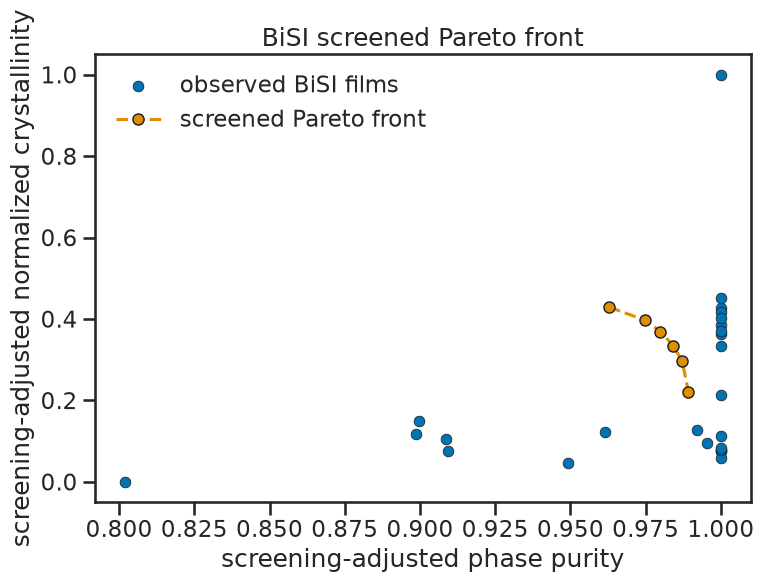

In [8]:
# Observed Pareto front: screened metrics where neither objective can improve without hurting the other.
import matplotlib.pyplot as plt

from xrd_bo_optimization_tf import plotting

figure, axis = plt.subplots(figsize=(8, 6))
axis.scatter(
    df_bo["phase_purity_screened"],
    df_bo["crystallinity_norm_screened"],
    s=60,
    edgecolor="k",
    linewidth=0.5,
    label="observed BiSI films",
    zorder=2,
)
if not df_pareto.empty:
    axis.plot(
        df_pareto["phase_purity_screened"],
        df_pareto["crystallinity_norm_screened"],
        "o--",
        color=plotting.COLOR_IMPURITY,
        markersize=8,
        markeredgecolor="k",
        label="screened Pareto front",
        zorder=3,
    )
axis.set_xlabel("screening-adjusted phase purity")
axis.set_ylabel("screening-adjusted normalized crystallinity")
axis.set_title("BiSI screened Pareto front")
axis.legend(frameon=False)
figure.tight_layout()
figure.savefig(
    plotting.FIGURES_DIR / "bisi_ax_pareto_front.png", dpi=150, bbox_inches="tight"
)
plt.show()

In [ ]:
# Compare Ax Pareto candidates with notebook 3's BiSI scalar-objective proposals.
from xrd_bo_optimization_tf.config import RESULTS_DATA_DIR

skopt_path = RESULTS_DATA_DIR / "bisi_bo_suggestions.csv"
if skopt_path.is_file():
    df_skopt = pd.read_csv(skopt_path)
    common = ["rank", *BO_PARAMS]
    comparison = pd.concat(
        {
            "Ax (screened MOO)": df_ax.reindex(columns=common),
            "skopt (screened weighted)": df_skopt.reindex(columns=common),
        },
        axis=0,
    )
    print("Ax optimizes separate screened phase-purity and crystallinity objectives; notebook 3 optimizes their weighted scalar score.")
    display(comparison.round(4))
else:
    print(f"BiSI skopt suggestions not found at {skopt_path}; run notebook 3 first")

Both workflows use the same five inputs and λ=0.25; Ax maximizes two screened outcomes while skopt maximizes their weighted scalar score.
Four numeric process inputs use recipe grids; pulse duty cycle is a continuous GP input, quantized to 1 ms timing recipes.


rank  hard_bake_temp_c  selenization_temp_c  \
Ax (screened MOO)         0     1             250.0                530.0   
                          1     2             225.0                540.0   
                          2     3             250.0                550.0   
                          3     4             225.0                530.0   
                          4     5             250.0                530.0   
skopt (screened weighted) 0     1             225.0                540.0   
                          1     2             225.0                540.0   
                          2     3             225.0                540.0   
                          3     4             225.0                540.0   
                          4     5             225.0                540.0   

                             selenization_time_s  cbc_ratio  \
Ax (screened MOO)         0               1800.0       0.63   
                          1               1800.0       0.63   
                          2               1800.0       0.65   
                          3               1500.0       0.63   
                          4               1800.0       0.63   
skopt (screened weighted) 0               1800.0       0.71   
                          1               1800.0       0.63   
                          2               1800.0       0.71   
                          3               1800.0       0.65   
                          4               1800.0       0.65   

                             se_pulse_duty_cycle  se_pulse_on_ms  \
Ax (screened MOO)         0               0.1844             590   
                          1               0.1622             519   
                          2               0.1897             607   
                          3               0.2425             776   
                          4               0.1341             429   
skopt (screened weighted) 0               0.1575             504   
                          1               0.1653             529   
                          2               0.1675             536   
                          3               0.1703             545   
                          4               0.1728             553   

                             se_pulse_off_ms  se_pulse_period_ms  \
Ax (screened MOO)         0             2610                3200   
                          1             2681                3200   
                          2             2593                3200   
                          3             2424                3200   
                          4             2771                3200   
skopt (screened weighted) 0             2696                3200   
                          1             2671                3200   
                          2             2664                3200   
                          3             2655                3200   
                          4             2647                3200   

                             se_pulse_frequency_hz  
Ax (screened MOO)         0                 0.3125  
                          1                 0.3125  
                          2                 0.3125  
                          3                 0.3125  
                          4                 0.3125  
skopt (screened weighted) 0                 0.3125  
                          1                 0.3125  
                          2                 0.3125  
                          3                 0.3125  
                          4                 0.3125